In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [4]:
RANDOM_SEED = 42

In [5]:
true_raw = pd.read_csv("data/True.csv")

fake_raw = pd.read_csv("data/Fake.csv")

In [6]:
true = true_raw.copy()

fake = fake_raw.copy()

In [7]:
true.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [8]:
fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [9]:
true["fake"] = 0
fake["fake"] = 1

df = pd.concat([true, fake], ignore_index=True)

df = df.sample(frac=1, random_state=42).reset_index(drop=True) #shuffle the rows so they two classes are not separated

In [11]:
raw_counts = df["fake"].value_counts()

percentages = round(df["fake"].value_counts(normalize=True), 2)

percentage_repr = percentages.astype(str) + "%"

real_fake_stats = pd.concat([raw_counts.rename("count"), percentage_repr.rename("percentages"), ], axis=1)

real_fake_stats.index = real_fake_stats.index.map({1 : "Fake", 0: "True"})

real_fake_stats.index.name = None

real_fake_stats

,count,percentages
Fake,23481,0.52%
True,21417,0.48%


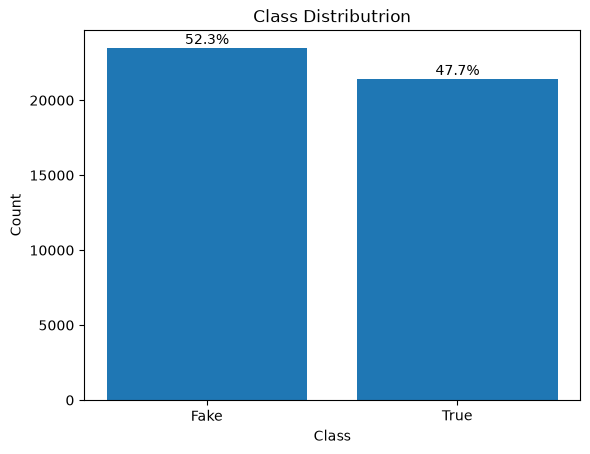

In [10]:
fig, ax = plt.subplots()

bars = ax.bar(real_fake_stats.index , real_fake_stats["count"])

ax.set_title("Class Distributrion")

ax.set_xlabel("Class")

ax.set_ylabel("Count")

ax.bar_label(bars, labels=real_fake_stats["percentages"], padding=0.5)

plt.show()

The two classes are ~52% and ~48%, this is relatively balanced, therefore accuracy metrics wont be misleading later on.

In [11]:
df["article_length"] = df["text"].str.split().str.len()
df["title_length"] = df["title"].str.split().str.len()
df["class"] = df["fake"].map({1: "Fake", 0: "True"}) #class label for visualizations

In [12]:
import seaborn as sns

<Axes: xlabel='class', ylabel='title_length'>

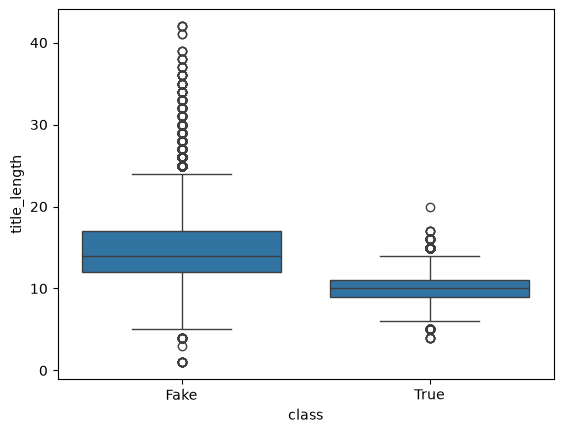

In [13]:


sns.boxplot(data= df, x= "class", y=  "title_length")

<Axes: xlabel='class', ylabel='article_length'>

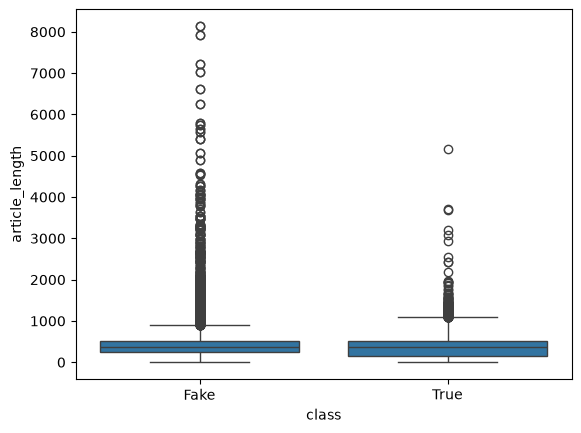

In [14]:
sns.boxplot(data= df, x= "class", y=  "article_length")

<Axes: xlabel='article_length', ylabel='Density'>

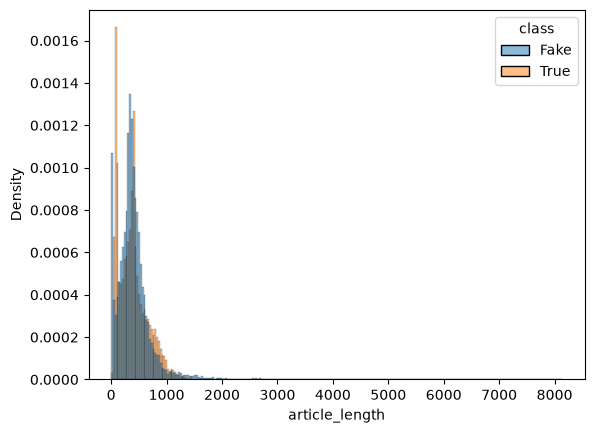

In [15]:
sns.histplot(data = df,
            x = "article_length",
            hue = "class",
            bins = 250,
            kde = False,
            common_norm= True,
            stat = "density")

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   title           44898 non-null  str  
 1   text            44898 non-null  str  
 2   subject         44898 non-null  str  
 3   date            44898 non-null  str  
 4   fake            44898 non-null  int64
 5   article_length  44898 non-null  int64
 6   title_length    44898 non-null  int64
 7   class           44898 non-null  str  
dtypes: int64(3), str(5)
memory usage: 2.7 MB


In [17]:
subject = df[["class","subject"]].value_counts()
subject

class  subject        
True   politicsNews       11272
       worldnews          10145
Fake   News                9050
       politics            6841
       left-news           4459
       Government News     1570
       US_News              783
       Middle-east          778
Name: count, dtype: int64

seems essentially unusable without sufficient auditing and validation. The categories between the two classes are very different, also what is "News"? all of them are news


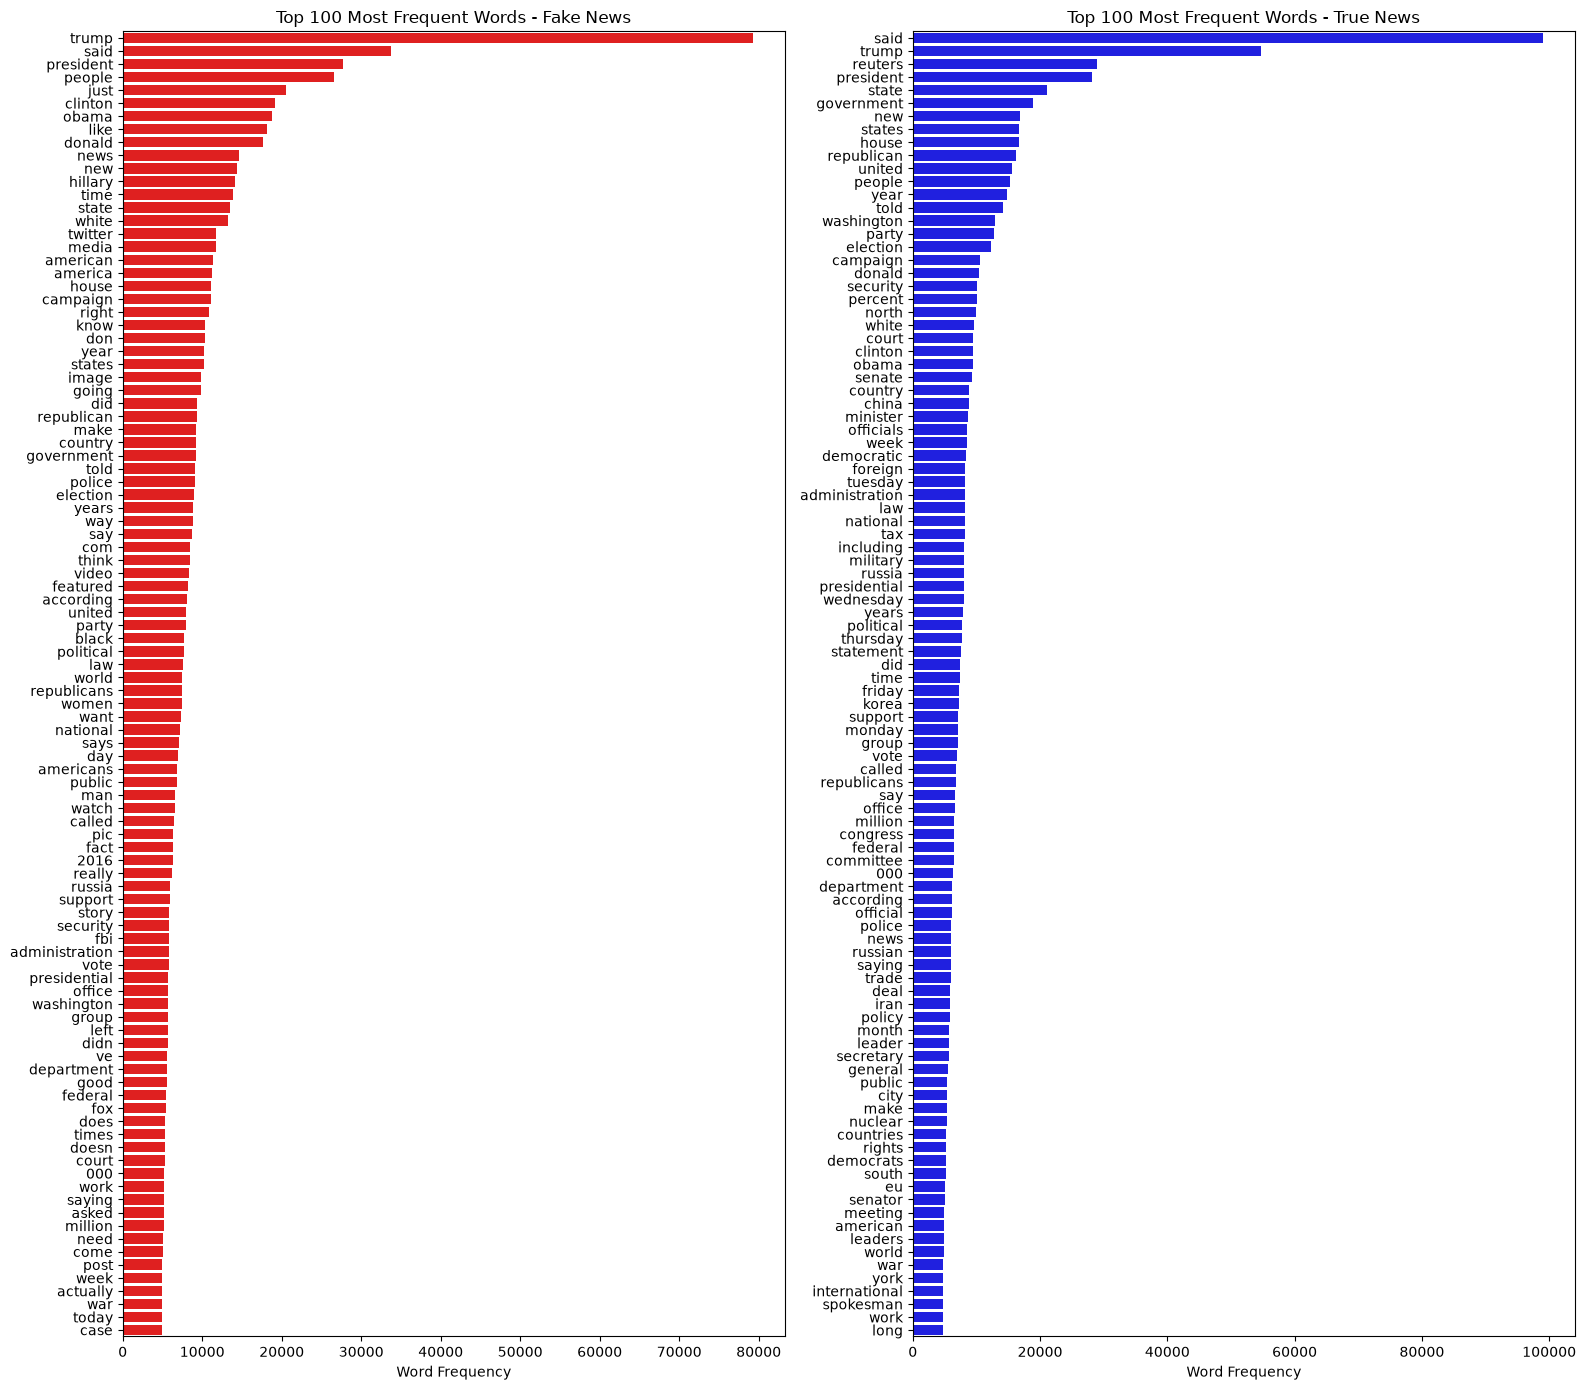

In [18]:

from sklearn.feature_extraction.text import CountVectorizer

fig, axes = plt.subplots(1, 2, figsize=(16, 14))

for ax, label, color in zip(
    axes,
    ["Fake", "True"],
    ["red", "blue"]
):
    texts = df.loc[df["class"] == label, "text"].fillna("")

    vectorizer = CountVectorizer(
        stop_words="english",
        max_features=100,
        min_df=2
    )

    X = vectorizer.fit_transform(texts)

    word_counts = X.sum(axis=0).A1
    words = vectorizer.get_feature_names_out()

    sns.barplot(
        x=word_counts,
        y=words,
        ax=ax,
        color=color,
        order=words[word_counts.argsort()[::-1]]
    )

    ax.set_title(f"Top 100 Most Frequent Words - {label} News")
    ax.set_xlabel("Word Frequency")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

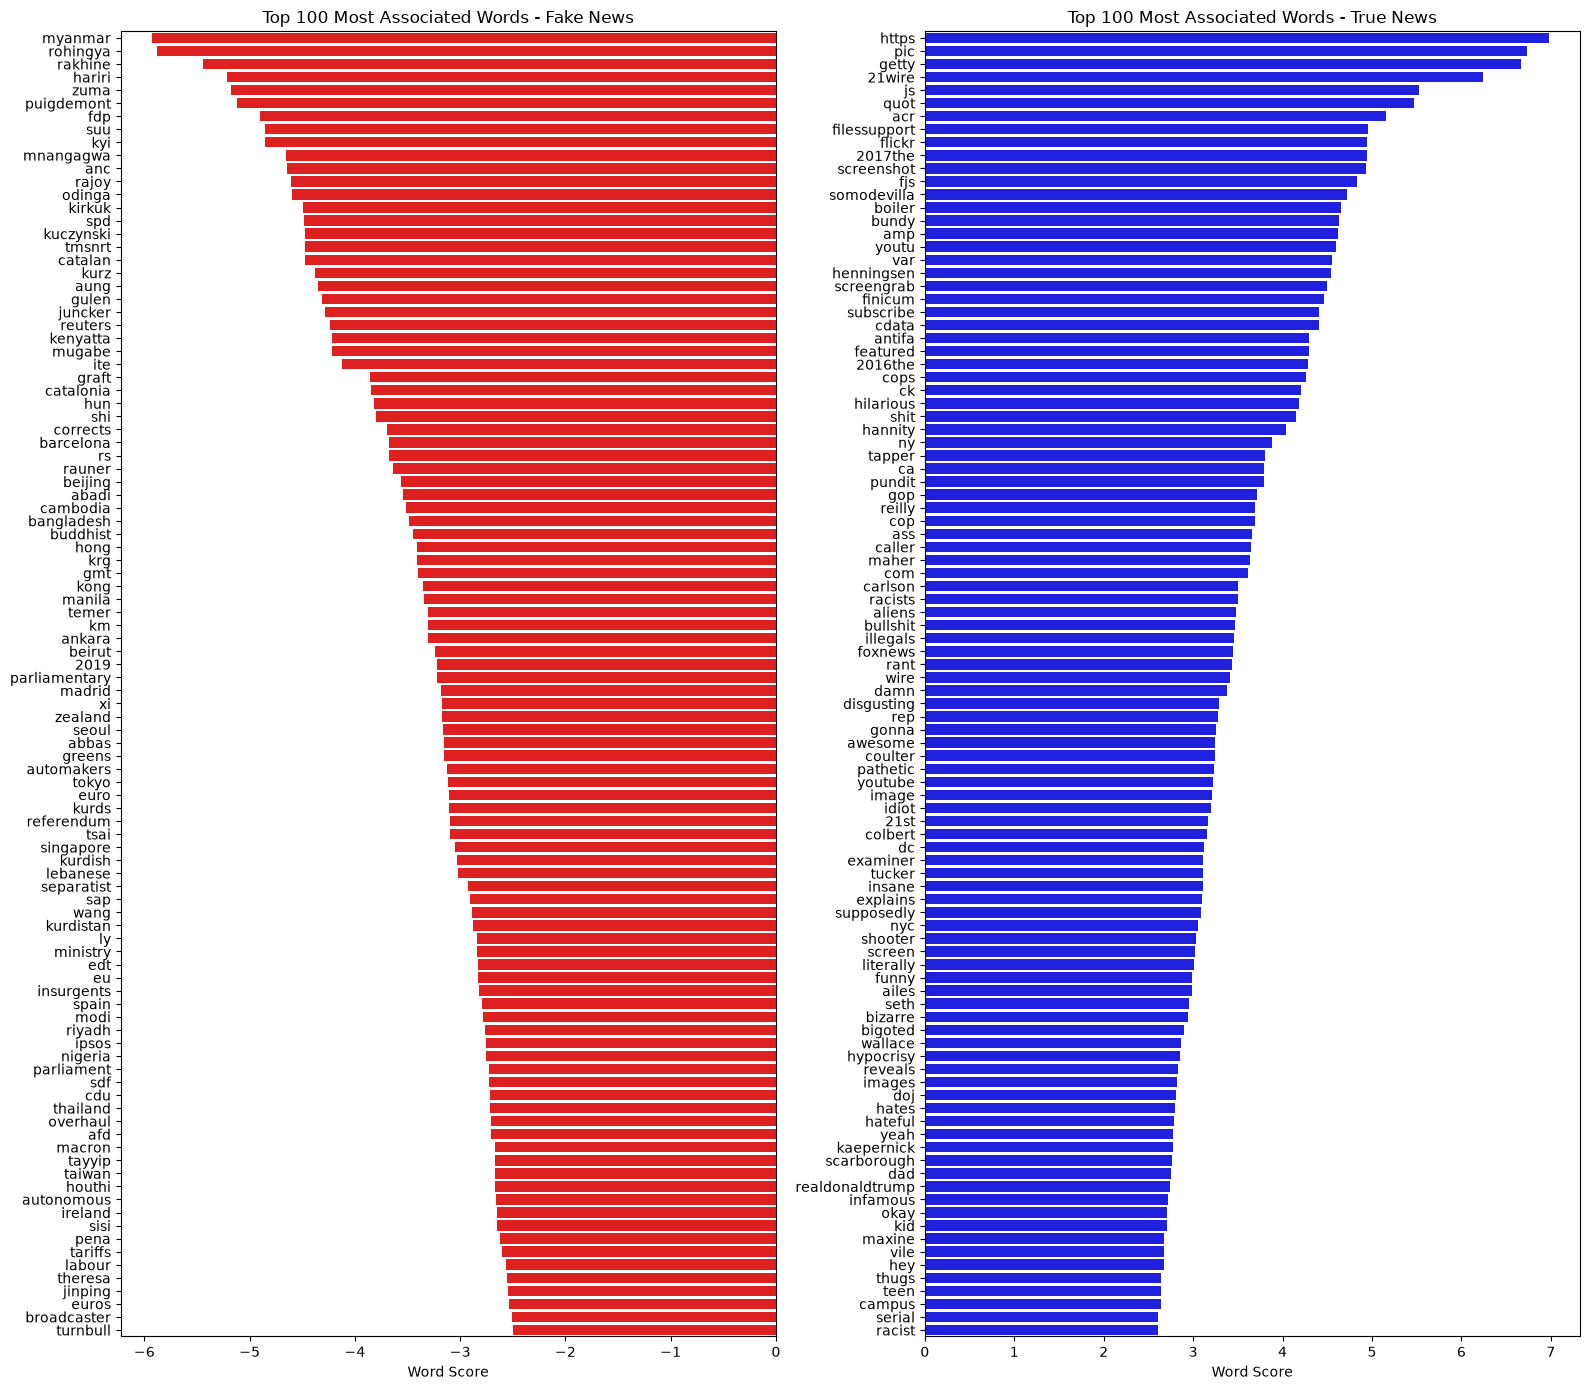

In [31]:
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=2
)

X = vectorizer.fit_transform(df["text"].fillna(""))

words = vectorizer.get_feature_names_out()

fake_counts = np.asarray(
    X[(df["class"] == "Fake").to_numpy()].sum(axis=0)
).ravel()

true_counts = np.asarray(
    X[(df["class"] == "True").to_numpy()].sum(axis=0)
).ravel()

fake_freq = fake_counts / fake_counts.sum()

true_freq = true_counts / true_counts.sum()
alpha =  1e-6
log_scores = np.log((fake_freq + alpha)/ (true_freq + alpha))


fig, axes = plt.subplots(1, 2, figsize=(16, 14))

for ax, label, color in zip(
    axes,
    ["Fake", "True"],
    ["red", "blue"]
):
    class_words = pd.DataFrame({
    "words" : words,
    "log_scores" : log_scores
    }
    )
    ascending = True if label == "Fake" else False

    class_words = class_words.sort_values("log_scores", ascending = ascending).head(100)

    sns.barplot(
        data = class_words,
        x = "log_scores",
        y = "words",
        ax=ax,
        color=color
    )

    ax.set_title(f"Top 100 Most Associated Words - {label} News")
    ax.set_xlabel("Word Score")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()